<a href="https://colab.research.google.com/github/jelianeys21/procesamiento-imagenes/blob/main/S8_PDIYVA_apertura-cierre-perimetro-gradiente.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
!git clone https://github.com/giancarlo92/curso_pdi

Cloning into 'curso_pdi'...
remote: Enumerating objects: 108, done.
remote: Counting objects: 100% (108/108), done.
remote: Compressing objects: 100% (102/102), done.
remote: Total 108 (delta 31), reused 21 (delta 1), pack-reused 0
Receiving objects: 100% (108/108), 1.41 MiB | 10.79 MiB/s, done.
Resolving deltas: 100% (31/31), done.


**APERTURA**

In [ ]:
from curso_pdi.funciones.dilatacion import dilatacion
from curso_pdi.funciones.erosion import erosion
def apertura(imagen, elemento_estructural):
  imagen_erosionada = erosion(imagen, elemento_estructural)
  imagen_dilatada = dilatacion(imagen_erosionada, elemento_estructural)
  return imagen_dilatada

**CIERRE**

In [ ]:
def cierre(imagen, elemento_estructural):
  imagen_dilatada = dilatacion(imagen, elemento_estructural)
  imagen_erosionada = erosion(imagen_dilatada, elemento_estructural)
  return imagen_erosionada

**PERIMETRO**

In [ ]:
def perimetro(imagen, elemento_estructural):
  imagen_erosionada = erosion(imagen, elemento_estructural)
  resultado = imagen - imagen_erosionada
  return resultado

**GRADIENTE**

In [ ]:
from curso_pdi.funciones.dilatacion import dilatacion
from curso_pdi.funciones.erosion import erosion
def gradiente(imagen, elemento_estructural):
  imagen_dilatada = dilatacion(imagen, elemento_estructural)
  imagen_erosionada = erosion(imagen, elemento_estructural)
  resultado = abs(imagen_dilatada - imagen_erosionada)
  return resultado

**APLICANDO MORFOLOGIA**

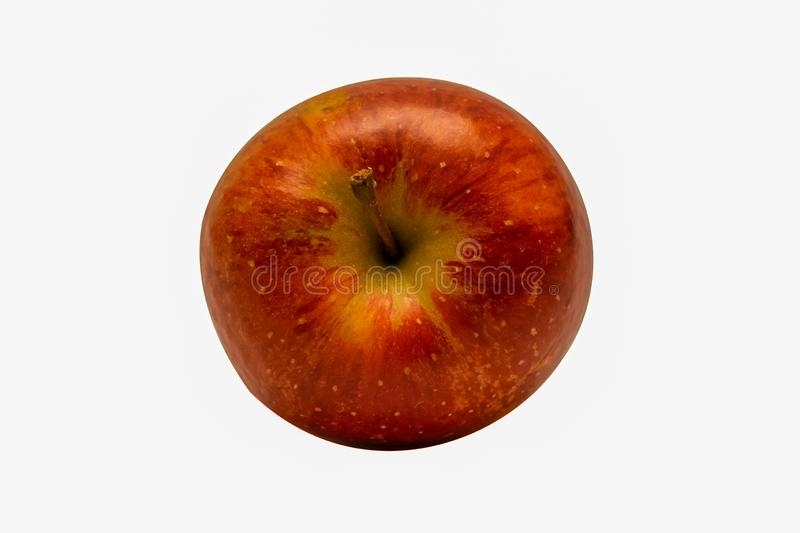

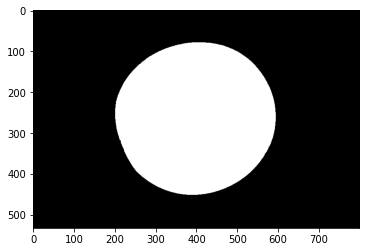

In [ ]:
# CIERRE extenso
imagen_manzana = cv2.imread("/content/curso_pdi/imagenes/clase8/manzana-desde-arriba.jpg")
cv2_imshow(imagen_manzana)
# convertir a gris
imagen_manzana_gris = cv2.cvtColor(imagen_manzana, cv2.COLOR_BGR2GRAY)
# cv2_imshow(imagen_manzana_gris)
# binarizacion
umbral = 130
imagen_manzana_binario = imagen_manzana_gris > umbral
plt.gray()
# plt.imshow(imagen_manzana_binario)
# negativo
imagen_manzana_negativo = 1 - imagen_manzana_binario
# plt.imshow(imagen_manzana_negativo)
# Aplicar cierre
elemento_estructural = np.ones((24, 24))
imagen_manzana_cierre = cierre(imagen_manzana_negativo, elemento_estructural)
plt.imshow(imagen_manzana_cierre)

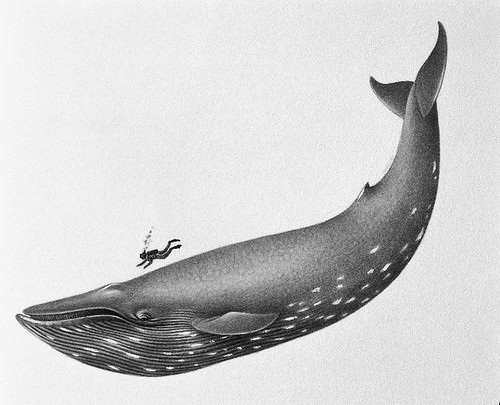

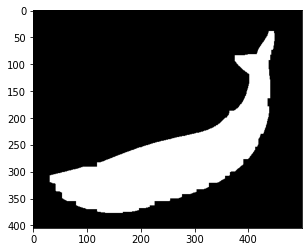

In [ ]:
# APERTURA resumida
ballena_hombre = cv2.imread("/content/curso_pdi/imagenes/clase8/ballena-hombre.jpg", 0)
cv2_imshow(ballena_hombre)
# negativo
umbral = 200
ballena_hombre_negativo = ballena_hombre < umbral
# plt.imshow(ballena_hombre_negativo)
# aplicar apertura
elemento_estructural = np.ones((10, 10))
ballena_hombre_apertura = apertura(ballena_hombre_negativo, elemento_estructural)
# plt.imshow(ballena_hombre_apertura)
# aplicando cierre
elemento_estructural2 = np.ones((13, 13))
ballena_hombre_cierre = cierre(ballena_hombre_apertura, elemento_estructural2)
plt.imshow(ballena_hombre_cierre)

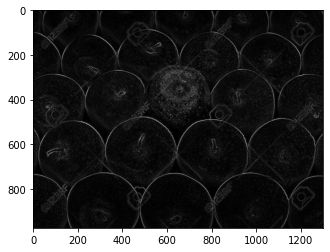

In [ ]:
# PERIMETRO
manzana_colores = cv2.imread("/content/curso_pdi/imagenes/clase8/manzanas-verdes-roja.jpg", 0)
#cv2_imshow(manzana_colores)
elemento_estructural = np.ones((5,5))
manzana_colores_perimetro = perimetro(manzana_colores, elemento_estructural)
plt.imshow(manzana_colores_perimetro)

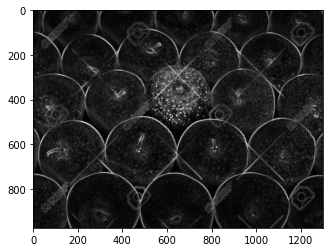

In [ ]:
#GRADIENTE
manzana_colores = cv2.imread("/content/curso_pdi/imagenes/clase8/manzanas-verdes-roja.jpg", 0)
#cv2_imshow(manzana_colores)
elemento_estructural = np.ones((5,5))
manzana_colores_gradiente = gradiente(manzana_colores, elemento_estructural)
plt.imshow(manzana_colores_gradiente)

**OPEN CV**

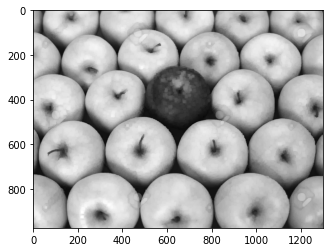

In [ ]:
elemento_estructural = np.ones((10, 10))
apertura = cv2.morphologyEx(manzana_colores, cv2.MORPH_OPEN, elemento_estructural)
plt.imshow(apertura)

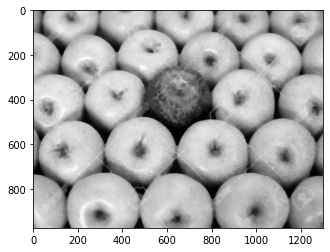

In [ ]:
elemento_estructural = np.ones((10, 10))
cierre = cv2.morphologyEx(manzana_colores, cv2.MORPH_CLOSE, elemento_estructural)
plt.imshow(cierre)

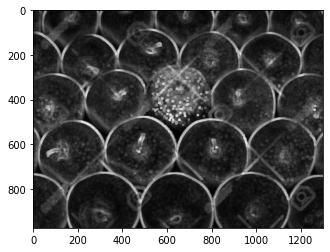

In [ ]:
elemento_estructural = np.ones((10, 10))
gradiente = cv2.morphologyEx(manzana_colores, cv2.MORPH_GRADIENT, elemento_estructural)
plt.imshow(gradiente)

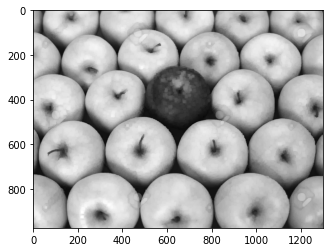

In [ ]:
elemento_estructural = np.ones((10, 10))
otro = cv2.morphologyEx(manzana_colores, cv2.MORPH_ELLIPSE, elemento_estructural)
plt.imshow(otro)

**GITHUB**

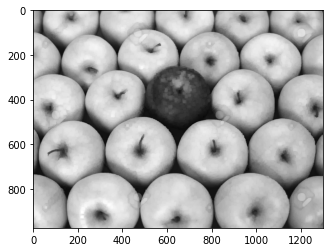

In [ ]:
from curso_pdi.funciones.apertura import apertura
elemento_estructural = np.ones((10, 10))
apertura2 = apertura(manzana_colores, elemento_estructural)
plt.imshow(apertura2)

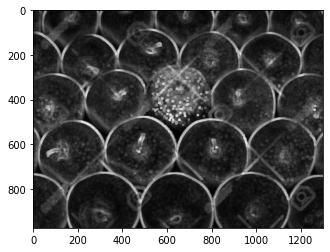

In [ ]:
from curso_pdi.funciones.gradiente import gradiente
elemento_estructural = np.ones((10, 10))
gradiente2 = gradiente(manzana_colores, elemento_estructural)
plt.imshow(gradiente2)